In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

results_path = "../results/"
h3_path = os.path.join(results_path, "h3/*.csv")

df_smax_120 = pd.read_csv(os.path.join(results_path, "solution_quality_test_smax_1.2.csv"))
df_smax_125 = pd.read_csv(os.path.join(results_path, "solution_quality_test_smax_1.25.csv"))
df_smax_inf = pd.read_csv(os.path.join(results_path, "solution_quality_test_smax_inf.csv"))

h3_result_files = glob.glob(h3_path)
df_h3 = pd.concat([pd.read_csv(f).assign(Instance=os.path.basename(f).replace('_h3.csv', '')) for f in h3_result_files])

sns.set_theme(style="whitegrid")

In [15]:
stats = df_smax_125.groupby(['Instance', 'Algorithm'])['Distance'].agg(['min', 'mean', 'std']).reset_index()
stats.columns = ['Instance', 'Algorithm', 'Best', 'Average', 'Std_Dev']

display(stats.sort_values(by=['Instance', 'Best']))

,Instance,Algorithm,Best,Average,Std_Dev
3,A-n32-k5.vrp,MMAS,791.569861,792.424961,0.717901
0,A-n32-k5.vrp,ASRank,799.096009,802.822654,3.182566
1,A-n32-k5.vrp,BasicAntSystem,811.971674,819.259273,5.854696
2,A-n32-k5.vrp,Greedy,1064.656130,1064.656130,NaN
7,A-n33-k6.vrp,MMAS,819.951556,877.944068,36.663775
4,A-n33-k6.vrp,ASRank,858.102253,921.204339,35.082923
5,A-n33-k6.vrp,BasicAntSystem,891.286997,930.150615,31.435002
6,A-n33-k6.vrp,Greedy,971.427572,971.427572,NaN
11,A-n36-k5.vrp,MMAS,870.372450,894.389899,16.930158
8,A-n36-k5.vrp,ASRank,890.552522,958.387108,43.624122


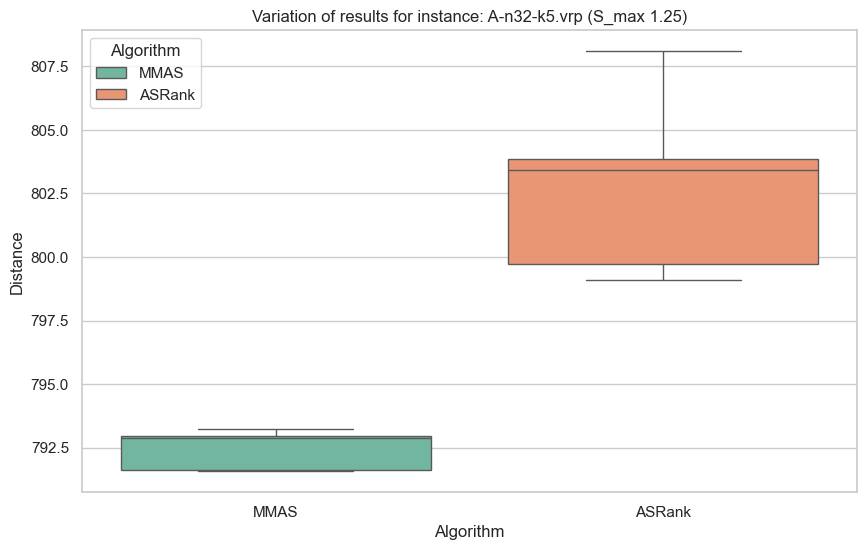

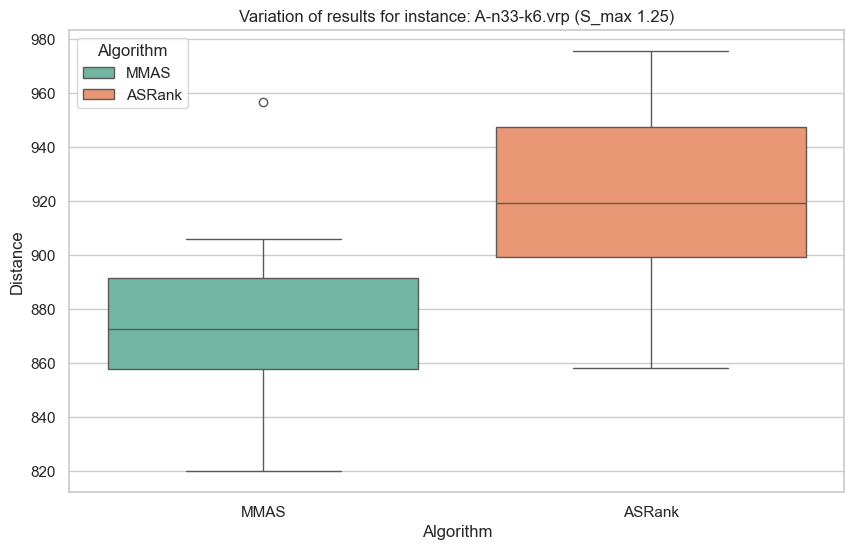

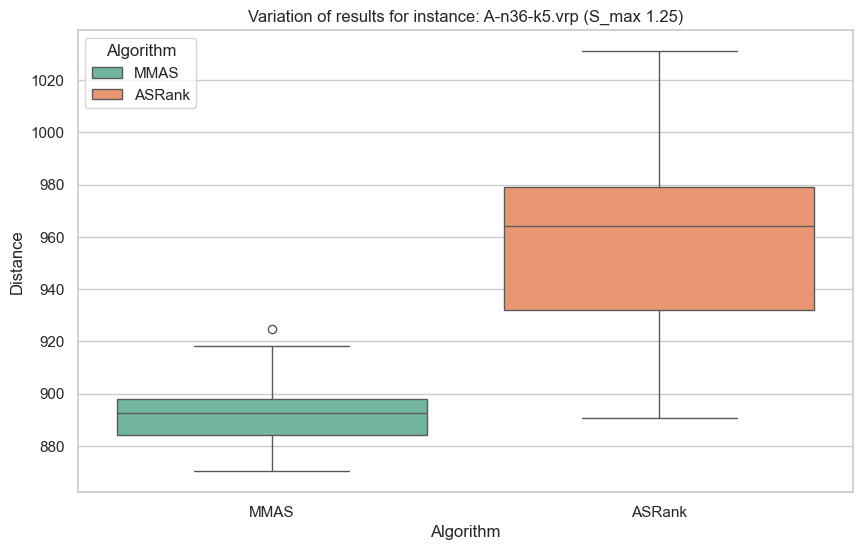

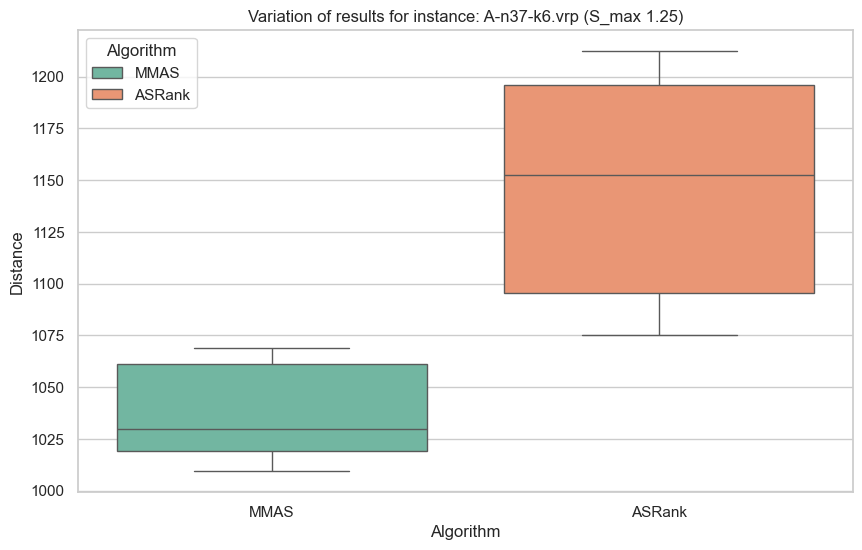

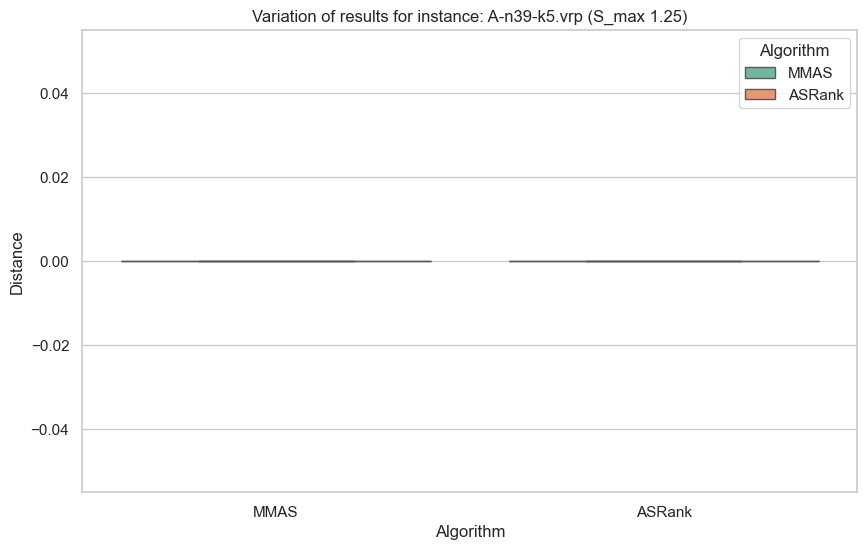

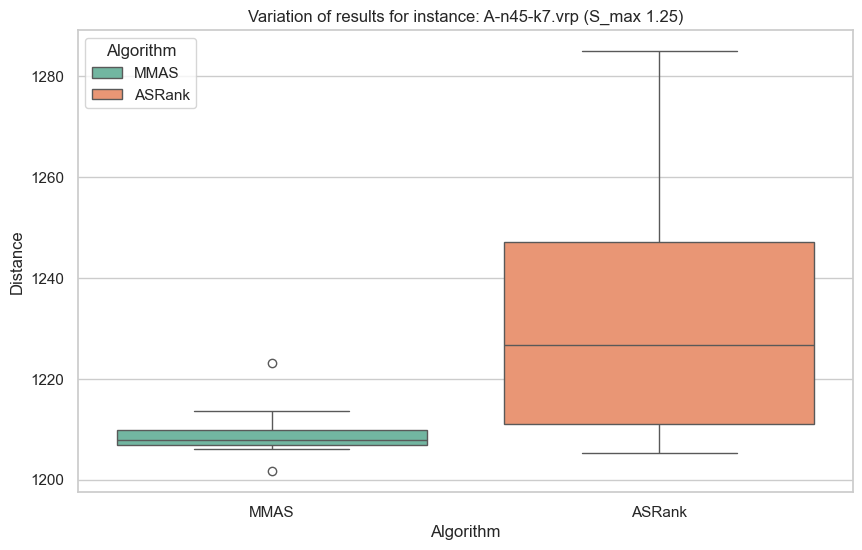

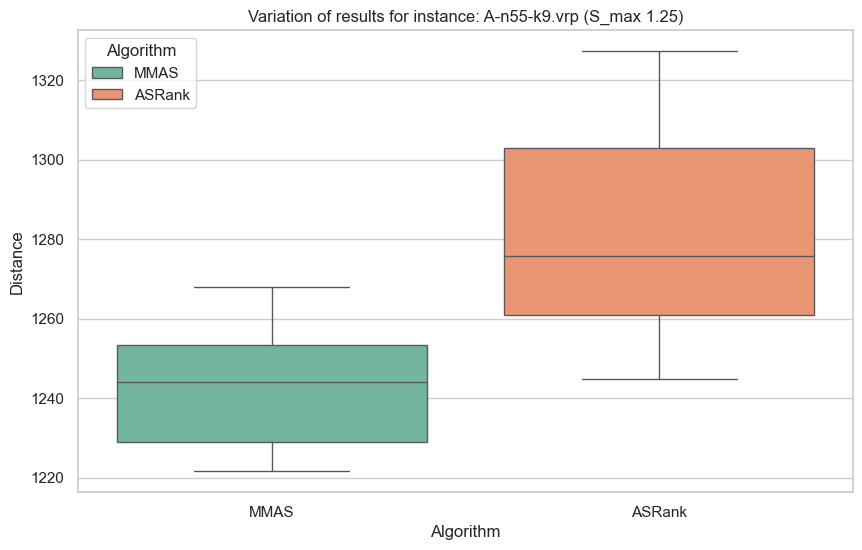

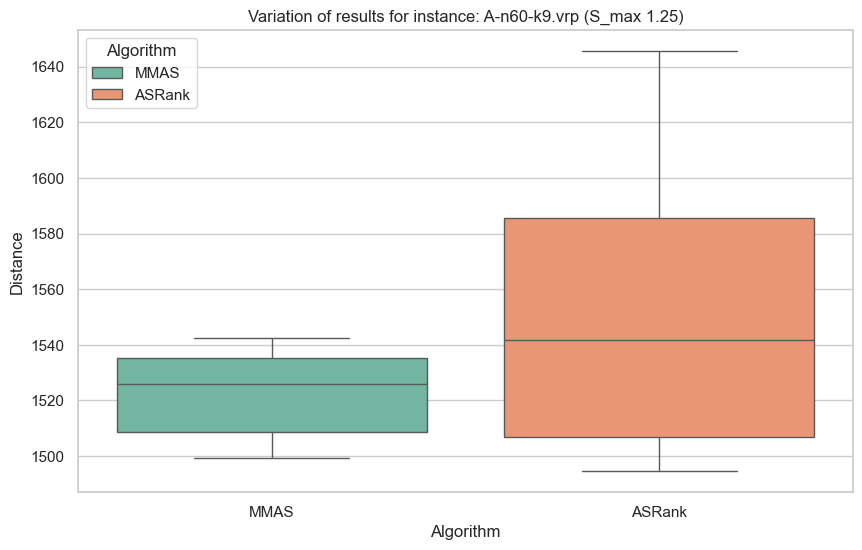

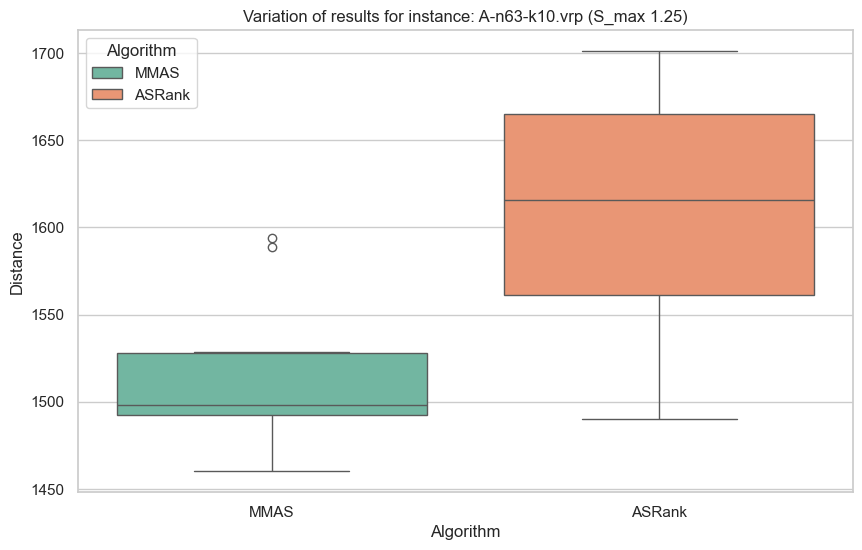

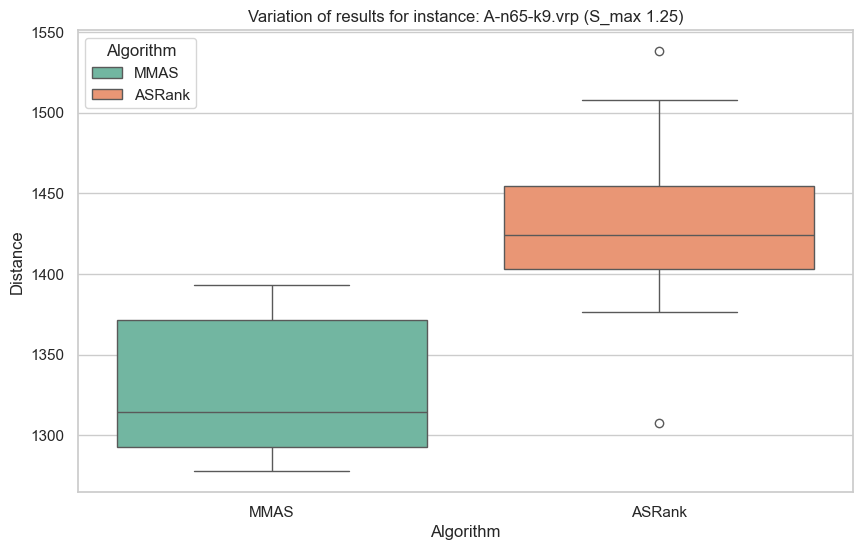

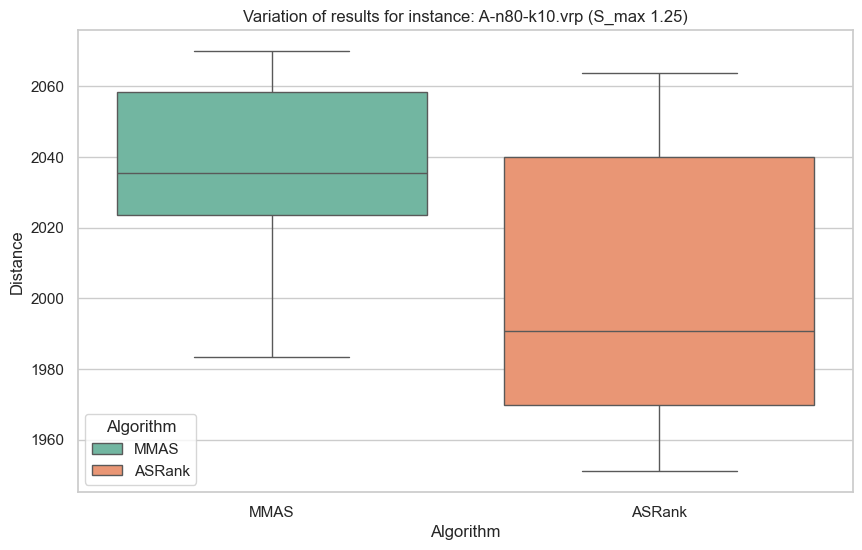

In [17]:
def plot_instance_boxplots(df, instance_name):
    plt.figure(figsize=(10, 6))
    data = df[df['Instance'] == instance_name].where(df['Algorithm'].isin(['MMAS', 'ASRank']))
    sns.boxplot(data=data, x='Algorithm', y='Distance', palette='Set2', hue="Algorithm")
    plt.title(f"Variation of results for instance: {instance_name} (S_max 1.25)")
    plt.show()

unique_instances = df_smax_125['Instance'].unique()
for inst in unique_instances:
    plot_instance_boxplots(df_smax_125, inst)

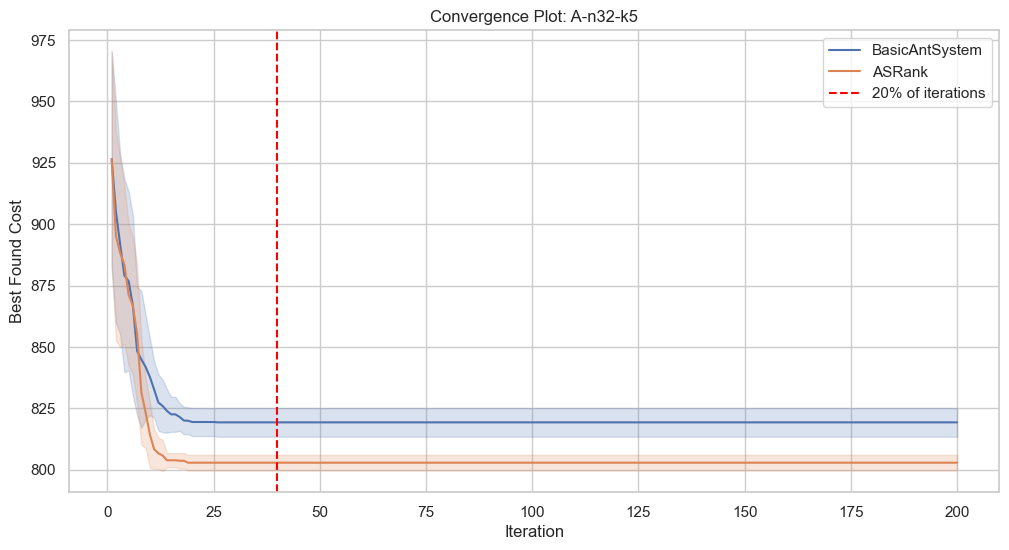

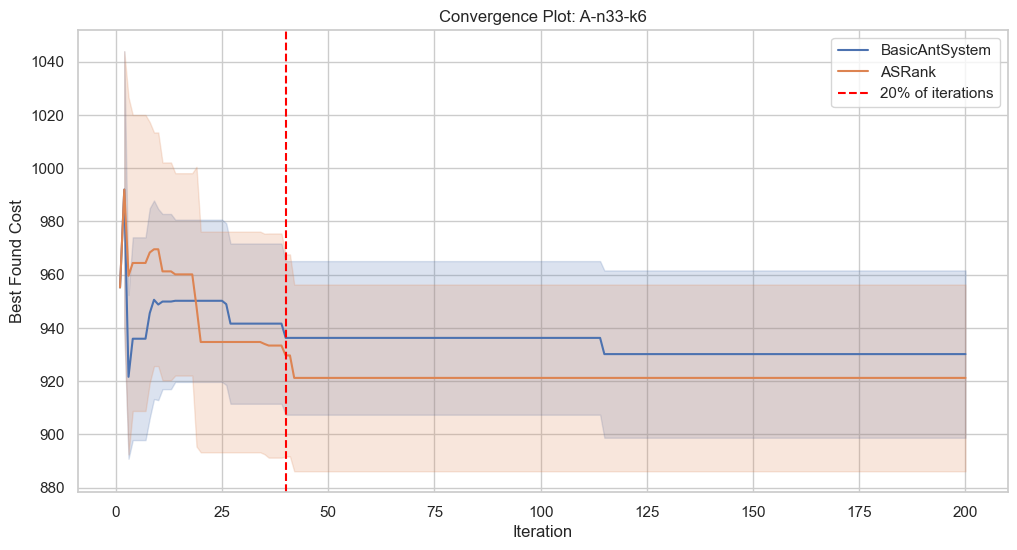

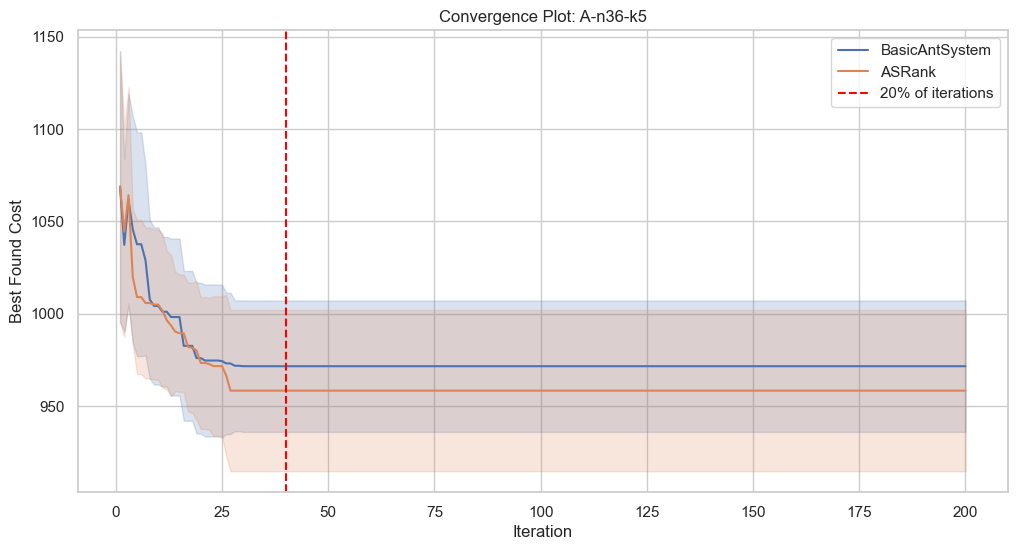

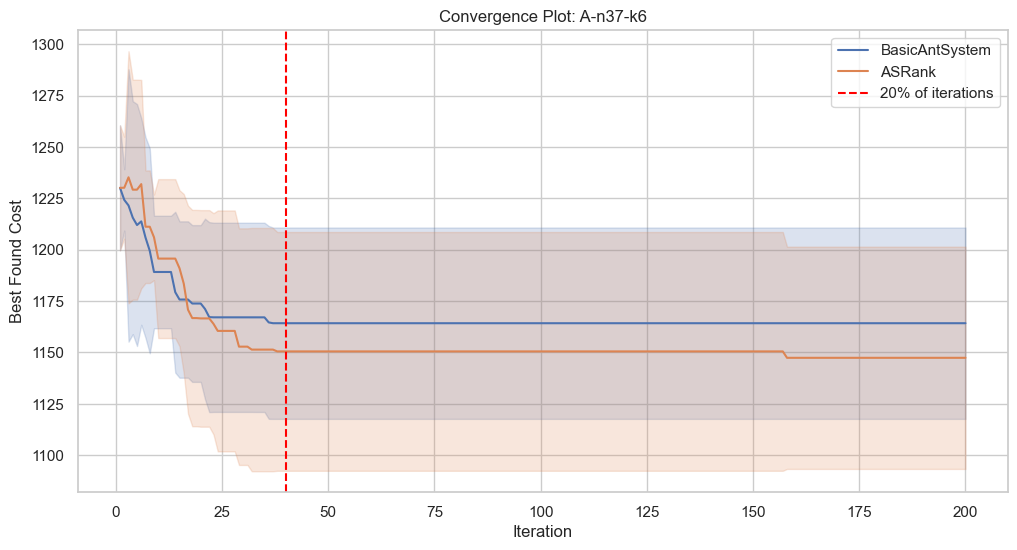

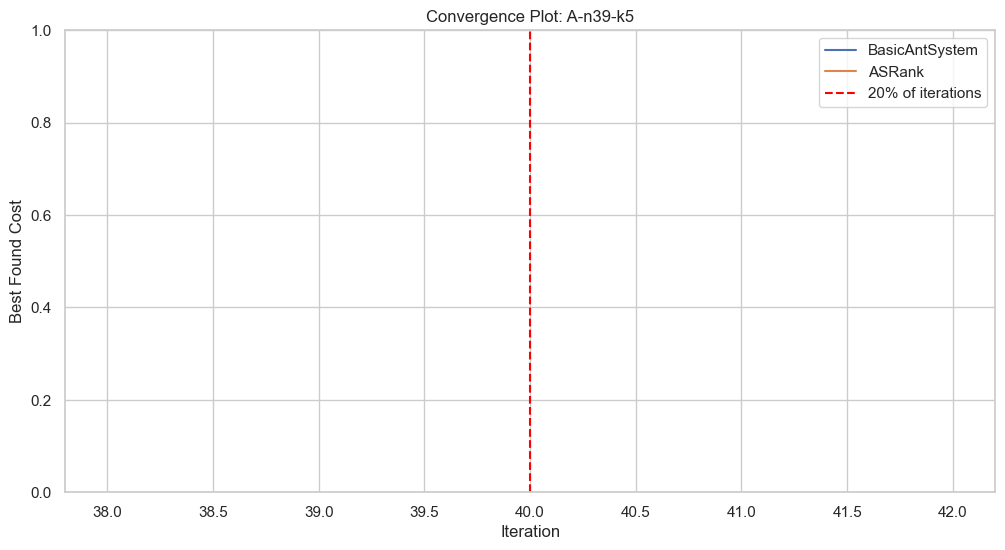

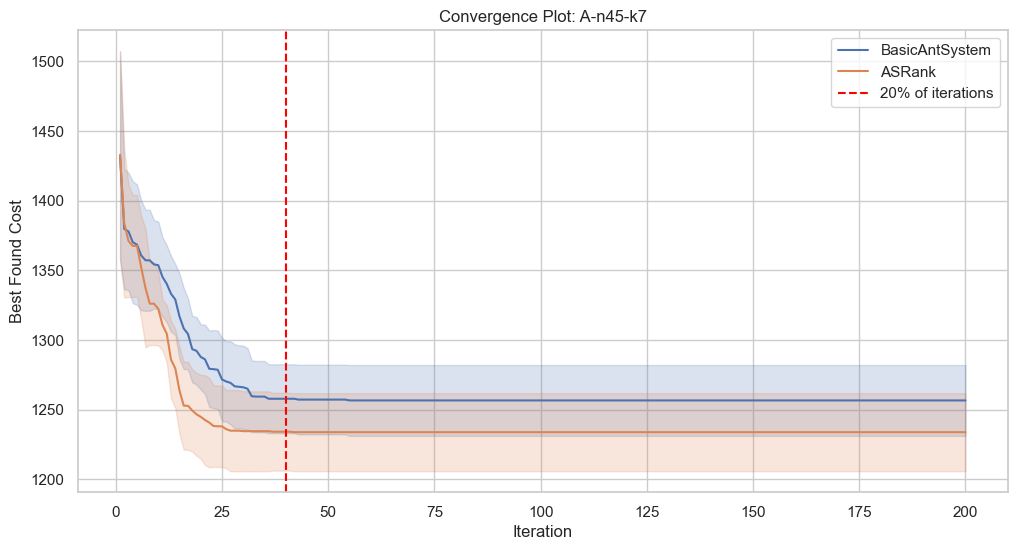

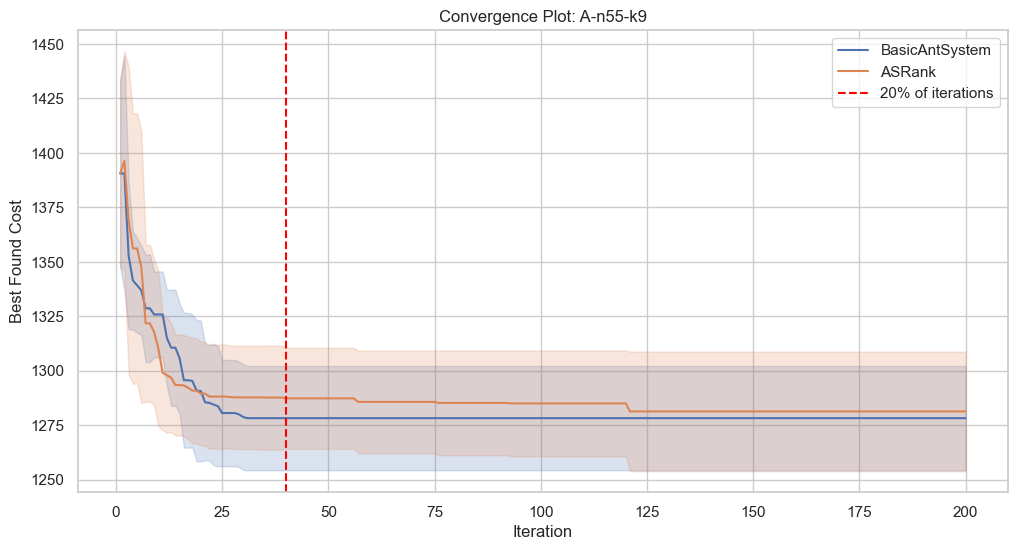

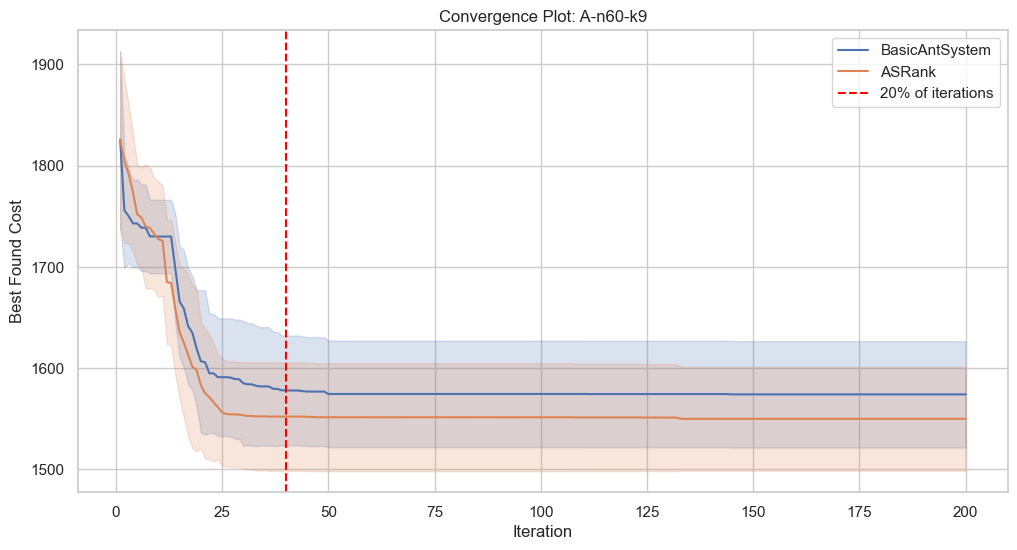

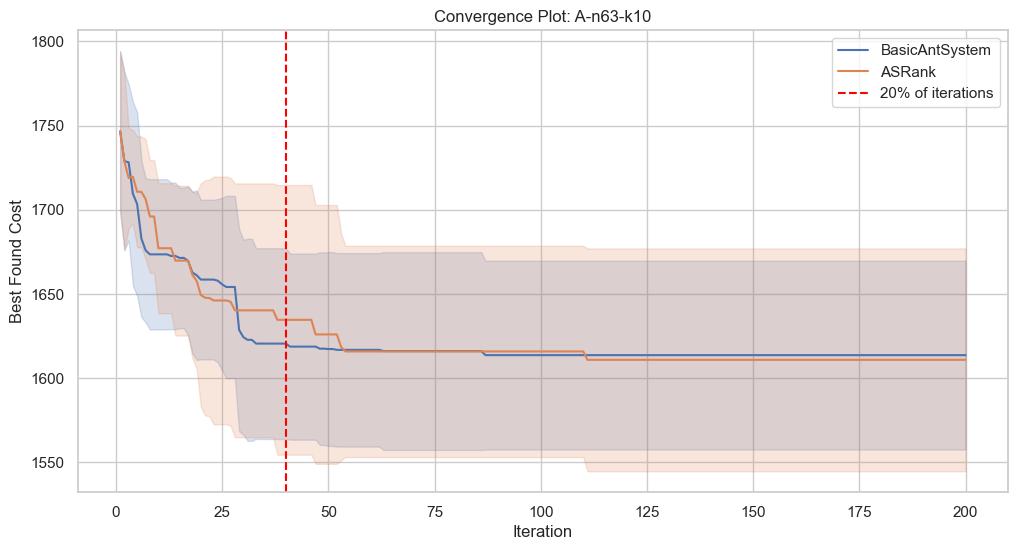

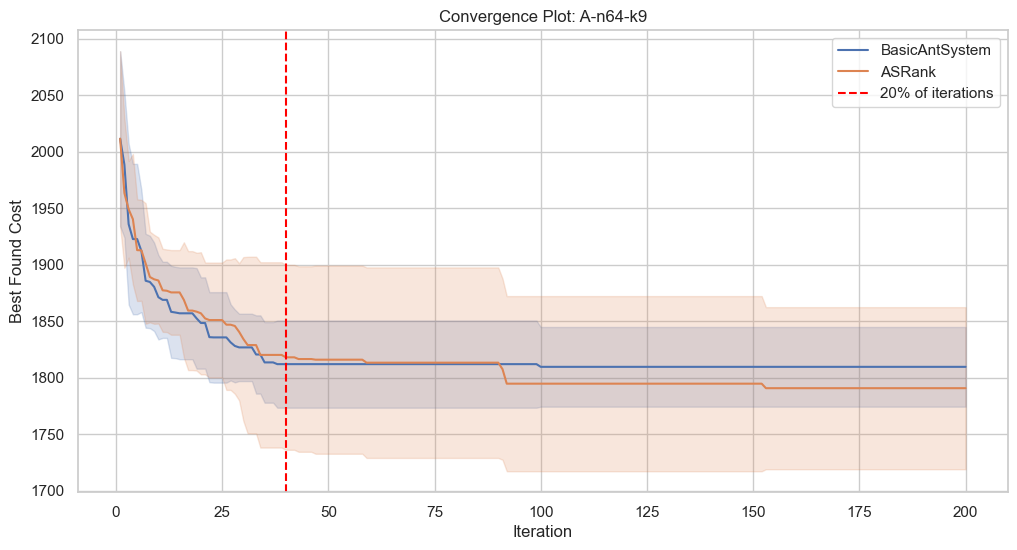

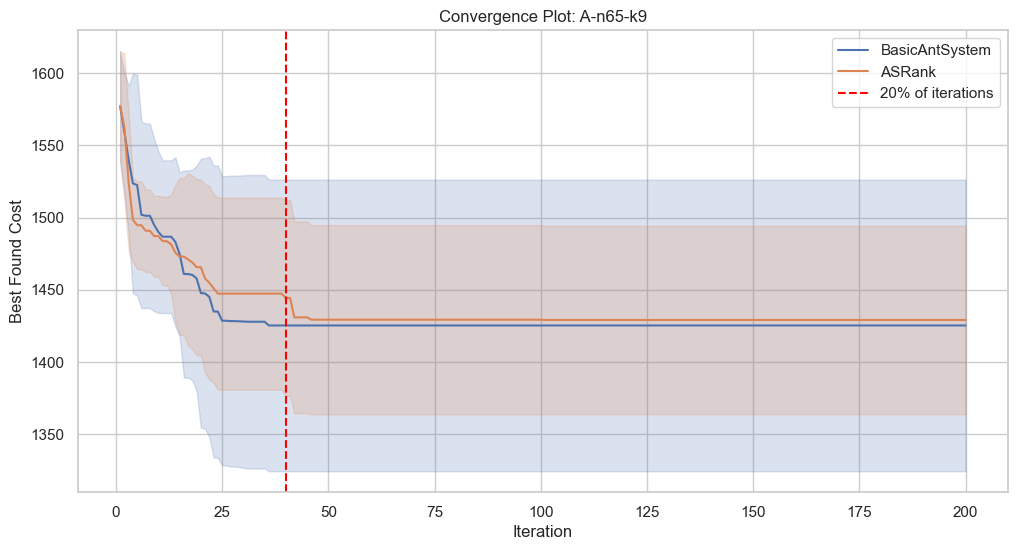

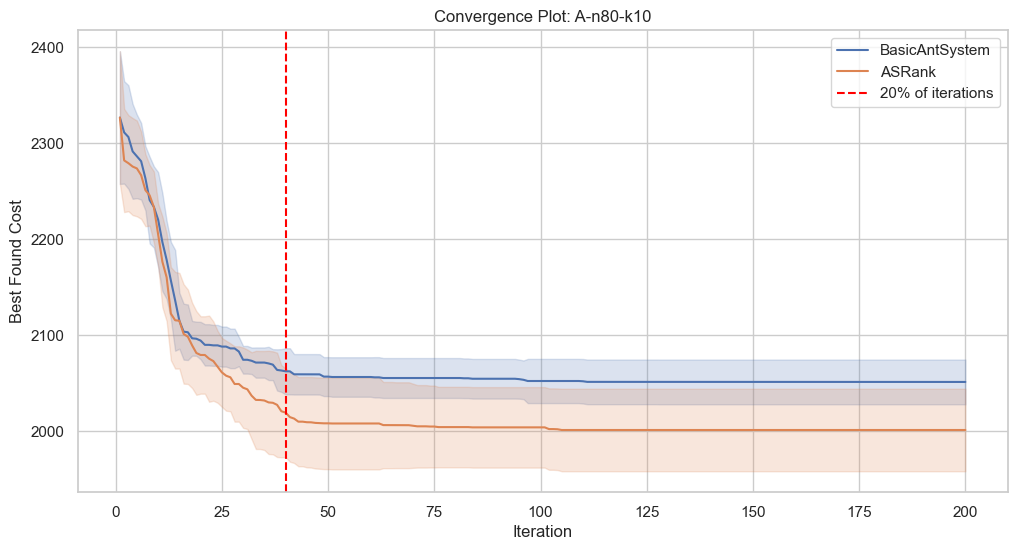

In [18]:
def plot_convergence(df_h3, instance_name):
    plt.figure(figsize=(12, 6))
    
    # Filter data for the specific instance
    inst_data = df_h3[df_h3['Instance'] == instance_name]

    # Draw line plot with standard deviation error bars
    sns.lineplot(data=inst_data, x='Iteration', y='Best_Cost', hue='Algorithm', errorbar='sd')
    
    # Draw line for 20% of iterations
    plt.axvline(x=40, color='red', linestyle='--', label='20% of iterations')
    
    plt.title(f"Convergence Plot: {instance_name}")
    plt.ylabel("Best Found Cost")
    plt.legend()
    plt.show()

for inst in df_h3['Instance'].unique():
    plot_convergence(df_h3, inst)